Using Colab cache for faster access to the 'telco-customer-churn' dataset.
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...         

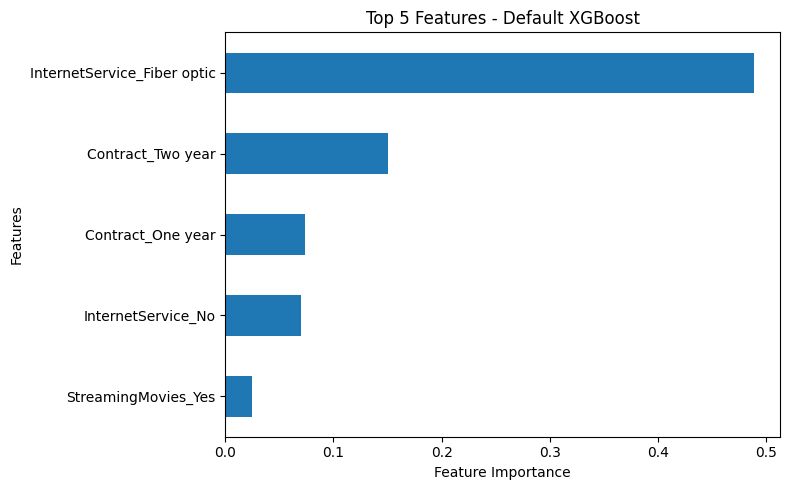

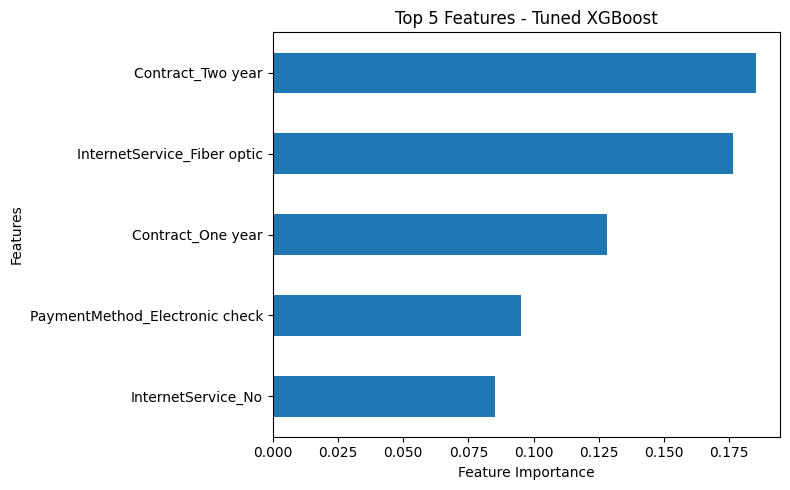


Best Model: AdaBoost
Best F1-Score: 0.6017441860465116


In [2]:
#%% Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

for file in os.listdir(path):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(path, file))
        break

print(df.head())

print("Dataset Shape:", df.shape)
print("\nFirst 10 Rows:")
print(df.head(10))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

#%% Handle TotalCharges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("\nMissing TotalCharges:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("\nMissing Values After Handling:")
print(df.isnull().sum())

# Median is used because it is less affected by extreme values than the mean.

#%% Drop CustomerID and Encode Target
df.drop("customerID", axis=1, inplace=True)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

#%% One-Hot Encoding
X = df.drop("Churn", axis=1)
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nEncoded Dataset Shape:", X.shape)

#%% Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#%% Train Default Models
models = {
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

results = []

def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    return model

for name, model in models.items():
    models[name] = evaluate_model(name, model)

#%% XGBoost GridSearchCV
xgb = XGBClassifier(random_state=42, eval_metric="logloss")

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest F1 Score:")
print(grid_search.best_score_)

#%% Evaluate Tuned XGBoost
best_xgb = grid_search.best_estimator_

evaluate_model("Tuned XGBoost", best_xgb)

#%% Compare Models
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.to_string(index=False))

#%% Feature Importance of Default and Tuned XGBoost
default_xgb = models["XGBoost"]

for name, model in [
    ("Default XGBoost", default_xgb),
    ("Tuned XGBoost", best_xgb)
]:
    importance = pd.Series(
        model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False).head(5)

    plt.figure(figsize=(8, 5))
    importance.sort_values().plot(kind="barh")
    plt.title("Top 5 Features - " + name)
    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()

#%% Best Model
best_result = results_df.loc[results_df["F1-Score"].idxmax()]

print("\nBest Model:", best_result["Model"])
print("Best F1-Score:", best_result["F1-Score"])